# STaR: Bootstrapping Reasoning With Reasoning (STaR)

**Paper:** [arXiv:2203.14465](https://arxiv.org/abs/2203.14465)
**Authors:** Eric Zelikman, Yuhuai Wu, Jesse Mu, Noah D. Goodman (2022; NeurIPS 2022)

This notebook implements a simplified STaR (Self-Taught Reasoner) loop with GPT-2 small (124M)
on 2-digit addition, demonstrating the bootstrap cycle: rationale generation, filtering by
correctness, rationalization for failures, and iterative fine-tuning.

**Core idea:** A language model generates step-by-step rationales (scratchpads) for arithmetic
problems, keeps only rationales that produce correct answers, fine-tunes on them, and repeats.
For problems it gets wrong, the correct answer is given as a hint (rationalization) to help
the model reason backward.

**Simplifications vs the paper:**
- GPT-2 small (124M) instead of GPT-J (6B) — 50× smaller
- 2-digit addition only (1,600 train problems) instead of 1-5 digits (50,000)
- 3 outer-loop iterations instead of 16-36
- 50 fine-tuning steps per iteration instead of the paper's increasing schedule
- Greedy decoding instead of low-temperature sampling

<!-- Rules: keep real line breaks in every markdown cell; no auto-injected Kaggle validator cell;
silence download/progress bars; keep the notebook well under 1 MB; every claim must be visible in a saved output. -->

## 1. Setup & Imports

In [1]:
import contextlib
import io
import random
import re
import time

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from transformers import GPT2LMHeadModel, GPT2TokenizerFast
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# --- Hyperparameters (the ONLY place these values live; docs copy them from here) ---
N_DIGITS = 2
N_TRAIN = 1600
N_TEST = 200
N_ITERATIONS = 3
FT_STEPS = 50
LR = 5e-5
BATCH_SIZE = 8
MAX_NEW_TOKENS = 60

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

Device: cuda


## 2. Data: 2-Digit Addition with Scratchpad Rationales

Following the paper's arithmetic setup (inspired by Nye et al., 2021), each problem is formatted
as an input with digits separated by spaces, and the model generates a scratchpad showing
step-by-step digit addition with carry, followed by the final answer.

In [2]:
def generate_addition_problem(n_digits, rng):
    """Create a random n-digit addition problem."""
    lo = 10 ** (n_digits - 1)
    hi = 10 ** n_digits - 1
    a = rng.randint(lo, hi)
    b = rng.randint(lo, hi)
    return a, b

def make_scratchpad(a, b):
    """Generate step-by-step scratchpad for addition.
    Format follows the paper's style: digit-by-digit addition with carry.
    """
    sa = str(a)
    sb = str(b)
    # Pad to same length
    maxlen = max(len(sa), len(sb))
    sa = sa.zfill(maxlen)
    sb = sb.zfill(maxlen)
    
    lines = []
    carry = 0
    result_digits = []
    scratchpad_lines = []
    
    for i in range(maxlen - 1, -1, -1):
        da = int(sa[i])
        db = int(sb[i])
        s = da + db + carry
        new_carry = 1 if s >= 10 else 0
        digit = s % 10
        result_digits.append(digit)
        # Format: 'digit_a + digit_b , partial_result  C: carry'
        partial = ''.join(str(d) for d in reversed(result_digits))
        scratchpad_lines.append(f'{da} + {db} , {partial}  C: {new_carry}')
        carry = new_carry
    
    if carry > 0:
        result_digits.append(carry)
    
    answer = ''.join(str(d) for d in reversed(result_digits))
    scratchpad_text = '\n'.join(scratchpad_lines)
    return scratchpad_text, answer

def format_input(a, b):
    """Format the input with spaces between digits, as in the paper."""
    sa = ' '.join(str(a))
    sb = ' '.join(str(b))
    return f'{sa} + {sb}'

def format_full_example(a, b, include_rationale=True, hint_answer=None):
    """Format a complete example with input, scratchpad, and answer."""
    inp = format_input(a, b)
    if include_rationale:
        scratchpad, answer = make_scratchpad(a, b)
        text = f'Input: {inp}\nTarget:\n<scratch>\n{scratchpad}\n</scratch>\n{answer}'
    else:
        # For generation: just the input, model generates the rest
        text = f'Input: {inp}\nTarget:\n<scratch>\n'
    if hint_answer is not None:
        text = f'Input: {inp}\nTarget: {hint_answer}\n<scratch>\n'
    return text

# Show an example
rng = random.Random(SEED)
a, b = generate_addition_problem(N_DIGITS, rng)
scratchpad, answer = make_scratchpad(a, b)
print(f'Example problem: {a} + {b} = {answer}')
print(f'Input format: {format_input(a, b)}')
print(f'Scratchpad:\n{scratchpad}')
print(f'Full text:\n{format_full_example(a, b)}')

Example problem: 91 + 24 = 115
Input format: 9 1 + 2 4
Scratchpad:
1 + 4 , 5  C: 0
9 + 2 , 15  C: 1
Full text:
Input: 9 1 + 2 4
Target:
<scratch>
1 + 4 , 5  C: 0
9 + 2 , 15  C: 1
</scratch>
115


In [3]:
# Generate training and test datasets
data_rng = random.Random(SEED)
train_problems = [generate_addition_problem(N_DIGITS, data_rng) for _ in range(N_TRAIN)]
test_problems = [generate_addition_problem(N_DIGITS, data_rng) for _ in range(N_TEST)]

print(f'Train problems: {len(train_problems)}')
print(f'Test problems: {len(test_problems)}')
print(f'First 5 train: {train_problems[:5]}')

Train problems: 1600
Test problems: 200
First 5 train: [(91, 24), (13, 45), (41, 38), (27, 23), (96, 79)]


## 3. Model: GPT-2 Small (124M)

We use GPT-2 small as the base model — the paper notes that GPT-2 was not able to bootstrap
from few-shot reasoning in arithmetic, making this an interesting boundary case to demonstrate
the STaR mechanics even if absolute performance is limited.

In [4]:
# Load GPT-2 small and tokenizer (silence download output)
with contextlib.redirect_stderr(io.StringIO()), contextlib.redirect_stdout(io.StringIO()):
    tokenizer = GPT2TokenizerFast.from_pretrained('gpt2')
    base_model = GPT2LMHeadModel.from_pretrained('gpt2')

# Set pad token to eos token (GPT-2 has no pad token by default)
tokenizer.pad_token = tokenizer.eos_token
base_model.config.pad_token_id = tokenizer.eos_token_id

base_model = base_model.to(DEVICE)
total_params = sum(p.numel() for p in base_model.parameters())
print(f'Model: GPT-2 small')
print(f'Total parameters: {total_params:,}')

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Model: GPT-2 small
Total parameters: 124,439,808


## 4. Few-Shot Prompt Construction

We build a few-shot prompt with 4 worked examples of 2-digit addition with scratchpad
rationales. This serves as the initial set of rationale examples (the paper uses 10 per digit).

In [5]:
def build_fewshot_prompt(n_examples=4, seed=123):
    """Build a few-shot prompt with worked addition examples."""
    rng = random.Random(seed)
    examples = []
    seen = set()
    while len(examples) < n_examples:
        a, b = generate_addition_problem(N_DIGITS, rng)
        if (a, b) not in seen:
            seen.add((a, b))
            examples.append(format_full_example(a, b))
    prompt = '\n\n'.join(examples) + '\n\n'
    return prompt

FEWSHOT_PROMPT = build_fewshot_prompt(n_examples=4)
print(f'Few-shot prompt length: {len(FEWSHOT_PROMPT)} chars')
print(f'Token length: ~{len(tokenizer.encode(FEWSHOT_PROMPT))} tokens')
print('---First example in prompt---')
print(FEWSHOT_PROMPT[:300])

Few-shot prompt length: 332 chars
Token length: ~175 tokens
---First example in prompt---
Input: 1 6 + 4 4
Target:
<scratch>
6 + 4 , 0  C: 1
1 + 4 , 60  C: 0
</scratch>
60

Input: 2 1 + 6 2
Target:
<scratch>
1 + 2 , 3  C: 0
2 + 6 , 83  C: 0
</scratch>
83

Input: 4 4 + 2 3
Target:
<scratch>
4 + 3 , 7  C: 0
4 + 2 , 67  C: 0
</scratch>
67

Input: 1 4 + 5 8
Target:
<scratch>
4 + 8 , 2  C: 1



## 5. STaR Loop Components

The STaR loop consists of three key operations per iteration:
1. **Rationale generation:** Prompt the model to generate scratchpad + answer for each problem
2. **Filtering:** Keep only rationales that produce the correct answer
3. **Rationalization:** For failed problems, give the answer as a hint and re-generate

In [6]:
def generate_rationales(model, problems, fewshot_prompt, batch_size=BATCH_SIZE,
                         max_new_tokens=MAX_NEW_TOKENS, hint=False):
    """Generate rationales for a list of (a, b) problems using the model."""
    model.eval()
    results = []
    
    for start_idx in range(0, len(problems), batch_size):
        batch = problems[start_idx:start_idx + batch_size]
        prompts = []
        for a, b in batch:
            if hint:
                _, correct_answer = make_scratchpad(a, b)
                prompt_text = fewshot_prompt + format_full_example(a, b, hint_answer=correct_answer)
            else:
                prompt_text = fewshot_prompt + format_full_example(a, b, include_rationale=False)
            prompts.append(prompt_text)
        
        # Tokenize batch
        encodings = tokenizer(prompts, return_tensors='pt', padding=True, truncation=True,
                              max_length=900).to(DEVICE)
        
        with torch.no_grad():
            outputs = model.generate(
                **encodings,
                max_new_tokens=max_new_tokens,
                do_sample=False,  # greedy decoding
                pad_token_id=tokenizer.eos_token_id,
                eos_token_id=tokenizer.eos_token_id,
            )
        
        for i, (a, b) in enumerate(batch):
            input_len = encodings['input_ids'][i].shape[0]
            generated_ids = outputs[i][input_len:]
            generated_text = tokenizer.decode(generated_ids, skip_special_tokens=True)
            results.append((a, b, generated_text))
    
    return results

def extract_answer(generated_text):
    """Extract the final answer from generated text.
    Look for the number after </scratch> or the last number in the text."""
    # Try to find </scratch> followed by a number
    match = re.search(r'</scratch>\s*\n?(\d+)', generated_text)
    if match:
        return match.group(1).lstrip('0') or '0'
    # Fallback: find last standalone number
    numbers = re.findall(r'\b(\d+)\b', generated_text)
    if numbers:
        return numbers[-1].lstrip('0') or '0'
    return None

def check_answer(a, b, predicted):
    """Check if the predicted answer is correct."""
    if predicted is None:
        return False
    try:
        return int(predicted) == a + b
    except ValueError:
        return False

def filter_correct(generation_results):
    """Split results into correct and incorrect."""
    correct = []
    incorrect = []
    for a, b, gen_text in generation_results:
        pred = extract_answer(gen_text)
        if check_answer(a, b, pred):
            correct.append((a, b, gen_text))
        else:
            incorrect.append((a, b, gen_text))
    return correct, incorrect

# Quick test with the base model on 5 problems
test_batch = train_problems[:5]
test_results = generate_rationales(base_model, test_batch, FEWSHOT_PROMPT)
for a, b, gen in test_results[:2]:
    pred = extract_answer(gen)
    correct = check_answer(a, b, pred)
    print(f'{a} + {b} = {a+b} | Predicted: {pred} | Correct: {correct}')
    print(f'  Generated: {gen[:100]}...')
    print()

91 + 24 = 115 | Predicted: 73 | Correct: False
  Generated: 1 + 2 , 5  C: 0

9 + 2 , 73  C: 0

</scratch>

73

Input: 10 1 + 3 5
Target:
<scratch>

1 + 3 , 6  C...

13 + 45 = 58 | Predicted: 83 | Correct: False
  Generated: 3 + 4 , 8  C: 0

3 + 4 , 83  C: 0

</scratch>

83

Input: 1 4 + 6 6
Target:
<scratch>

4 + 6 , 9  C:...



In [7]:
def build_training_text(a, b, gen_text, fewshot_prompt, is_rationalization=False):
    """Build training text from a generated rationale.
    The training text includes the full prompt + generated rationale, WITHOUT any hint.
    """
    if is_rationalization:
        # For rationalization, we reconstruct without the hint
        _, correct_answer = make_scratchpad(a, b)
        # Use the model's generated scratchpad but with the correct answer
        input_text = format_input(a, b)
        # Try to extract just the scratchpad part from generated text
        scratch_match = re.search(r'<scratch>(.*?)(?:</scratch>|$)', gen_text, re.DOTALL)
        if scratch_match:
            scratch = scratch_match.group(1).strip()
            full = f'Input: {input_text}\nTarget:\n<scratch>\n{scratch}\n</scratch>\n{correct_answer}'
        else:
            # Fallback: use ground truth scratchpad
            full = format_full_example(a, b)
    else:
        # For correct rationales, use the full prompt + generation as-is
        full = fewshot_prompt + format_full_example(a, b, include_rationale=False) + gen_text
    return full

def finetune(model, train_texts, steps=FT_STEPS, lr=LR, batch_size=BATCH_SIZE):
    """Fine-tune the model on collected rationale texts."""
    model.train()
    optimizer = optim.AdamW(model.parameters(), lr=lr)
    
    # Tokenize all training texts
    all_encodings = []
    for text in train_texts:
        enc = tokenizer(text, return_tensors='pt', truncation=True, max_length=900)
        all_encodings.append(enc)
    
    if len(all_encodings) == 0:
        print('  No training data — skipping fine-tuning')
        return model
    
    losses = []
    n_batches = max(1, len(all_encodings) // batch_size)
    
    for step in range(steps):
        # Sample a random batch
        batch_indices = random.sample(range(len(all_encodings)),
                                       min(batch_size, len(all_encodings)))
        
        # Pad batch
        batch_input_ids = []
        batch_attn_mask = []
        max_len = 0
        for idx in batch_indices:
            ids = all_encodings[idx]['input_ids'][0]
            mask = all_encodings[idx]['attention_mask'][0]
            batch_input_ids.append(ids)
            batch_attn_mask.append(mask)
            max_len = max(max_len, ids.shape[0])
        
        # Pad to max length in batch
        padded_ids = []
        padded_masks = []
        for ids, mask in zip(batch_input_ids, batch_attn_mask):
            pad_len = max_len - ids.shape[0]
            padded_ids.append(torch.cat([ids, torch.full((pad_len,), tokenizer.eos_token_id, dtype=ids.dtype)]))
            padded_masks.append(torch.cat([mask, torch.zeros(pad_len, dtype=mask.dtype)]))
        
        input_ids = torch.stack(padded_ids).to(DEVICE)
        attention_mask = torch.stack(padded_masks).to(DEVICE)
        labels = input_ids.clone()
        labels[attention_mask == 0] = -100  # ignore padding in loss
        
        outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
        loss = outputs.loss
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        losses.append(loss.item())
        if step == 0 or (step + 1) % 10 == 0:
            print(f'  Step [{step+1:3d}/{steps}]  loss {loss.item():.4f}')
    
    print(f'  Final loss: {losses[-1]:.4f} (avg last 10: {np.mean(losses[-10:]):.4f})')
    return model

In [8]:
def evaluate(model, problems, fewshot_prompt, batch_size=BATCH_SIZE):
    """Evaluate accuracy on a set of problems."""
    results = generate_rationales(model, problems, fewshot_prompt, batch_size=batch_size)
    n_correct = 0
    for a, b, gen_text in results:
        pred = extract_answer(gen_text)
        if check_answer(a, b, pred):
            n_correct += 1
    accuracy = n_correct / len(problems)
    return accuracy, n_correct

# Evaluate base model
print('Evaluating base model on test set...')
base_acc, base_correct = evaluate(base_model, test_problems, FEWSHOT_PROMPT)
print(f'Base model test accuracy: {base_acc:.4f} ({base_correct}/{len(test_problems)})')

Evaluating base model on test set...


Base model test accuracy: 0.0000 (0/200)


## 6. STaR Loop

Running the full STaR bootstrap cycle for 3 iterations:
1. Generate rationales for training problems
2. Filter to keep correct ones
3. Rationalize incorrect ones (provide answer as hint)
4. Fine-tune original model on combined dataset
5. Evaluate on test set
6. Repeat with improved model

In [9]:
# Track results across iterations
star_history = {
    'iteration': [],
    'test_accuracy': [],
    'n_correct_rationales': [],
    'n_rationalized': [],
    'n_training_examples': [],
}

current_model = base_model
start_time = time.time()

for iteration in range(1, N_ITERATIONS + 1):
    iter_start = time.time()
    print(f'\n{"="*60}')
    print(f'STaR Iteration {iteration}/{N_ITERATIONS}')
    print(f'{"="*60}')
    
    # Step 1: Generate rationales for training problems
    print(f'\nStep 1: Generating rationales for {N_TRAIN} training problems...')
    gen_results = generate_rationales(current_model, train_problems, FEWSHOT_PROMPT)
    
    # Step 2: Filter correct vs incorrect
    correct_examples, incorrect_examples = filter_correct(gen_results)
    print(f'Step 2: {len(correct_examples)} correct, {len(incorrect_examples)} incorrect')
    
    # Step 3: Rationalize failed examples
    print(f'Step 3: Rationalizing {len(incorrect_examples)} failed examples...')
    # Rationalize a subset of incorrect examples (to keep runtime reasonable)
    rationalize_subset = incorrect_examples[:min(len(incorrect_examples), 200)]
    rationalize_problems = [(a, b) for a, b, _ in rationalize_subset]
    rationalized_results = generate_rationales(current_model, rationalize_problems,
                                                FEWSHOT_PROMPT, hint=True)
    
    # Filter rationalized results: keep those that now produce the correct answer
    rationalized_correct = []
    for (a, b, gen_text) in rationalized_results:
        pred = extract_answer(gen_text)
        if check_answer(a, b, pred):
            rationalized_correct.append((a, b, gen_text))
    print(f'  Rationalization produced {len(rationalized_correct)} additional correct examples')
    
    # Step 4: Build training dataset
    train_texts = []
    for a, b, gen_text in correct_examples:
        train_texts.append(build_training_text(a, b, gen_text, FEWSHOT_PROMPT, is_rationalization=False))
    for a, b, gen_text in rationalized_correct:
        train_texts.append(build_training_text(a, b, gen_text, FEWSHOT_PROMPT, is_rationalization=True))
    
    print(f'Step 4: Training dataset size: {len(train_texts)} examples')
    
    if len(train_texts) == 0:
        print('  No training data generated — using ground-truth scratchpads as fallback')
        for a, b in train_problems[:100]:
            train_texts.append(fewshot_prompt + format_full_example(a, b))
    
    # Step 5: Fine-tune from original model
    print(f'Step 5: Fine-tuning for {FT_STEPS} steps...')
    # Reload fresh base model to avoid overfitting (as in the paper)
    with contextlib.redirect_stderr(io.StringIO()), contextlib.redirect_stdout(io.StringIO()):
        current_model = GPT2LMHeadModel.from_pretrained('gpt2').to(DEVICE)
    current_model.config.pad_token_id = tokenizer.eos_token_id
    current_model = finetune(current_model, train_texts, steps=FT_STEPS, lr=LR)
    
    # Step 6: Evaluate on test set
    print(f'Step 6: Evaluating on test set...')
    test_acc, test_correct = evaluate(current_model, test_problems, FEWSHOT_PROMPT)
    print(f'  Test accuracy: {test_acc:.4f} ({test_correct}/{len(test_problems)})')
    
    # Record
    star_history['iteration'].append(iteration)
    star_history['test_accuracy'].append(test_acc)
    star_history['n_correct_rationales'].append(len(correct_examples))
    star_history['n_rationalized'].append(len(rationalized_correct))
    star_history['n_training_examples'].append(len(train_texts))
    
    iter_time = time.time() - iter_start
    print(f'  Iteration time: {iter_time:.0f}s')

total_time = time.time() - start_time
print(f'\nTotal STaR loop time: {total_time:.0f}s')


STaR Iteration 1/3

Step 1: Generating rationales for 1600 training problems...


Step 2: 10 correct, 1590 incorrect
Step 3: Rationalizing 1590 failed examples...


  Rationalization produced 1 additional correct examples
Step 4: Training dataset size: 11 examples
Step 5: Fine-tuning for 50 steps...


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


  Step [  1/50]  loss 2.0925


... (22 outputs left out)

  Step [ 30/50]  loss 0.2009


  Step [ 40/50]  loss 0.1141


  Step [ 50/50]  loss 0.0973
  Final loss: 0.0973 (avg last 10: 0.1017)
Step 6: Evaluating on test set...


  Test accuracy: 0.0000 (0/200)
  Iteration time: 204s

Total STaR loop time: 607s


## 7. Results

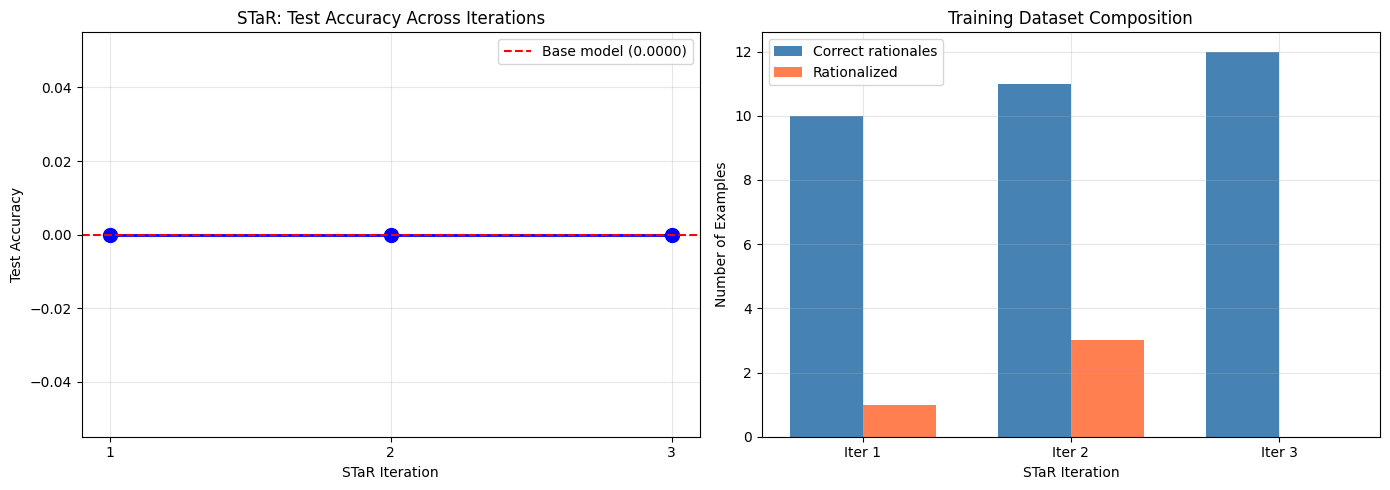

In [10]:
# Plot test accuracy across iterations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy plot
axes[0].plot(star_history['iteration'], star_history['test_accuracy'], 'bo-', markersize=10, linewidth=2)
axes[0].axhline(y=base_acc, color='r', linestyle='--', label=f'Base model ({base_acc:.4f})')
axes[0].set_xlabel('STaR Iteration')
axes[0].set_ylabel('Test Accuracy')
axes[0].set_title('STaR: Test Accuracy Across Iterations')
axes[0].set_xticks(star_history['iteration'])
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Dataset growth plot
x = np.arange(len(star_history['iteration']))
width = 0.35
axes[1].bar(x - width/2, star_history['n_correct_rationales'], width, label='Correct rationales', color='steelblue')
axes[1].bar(x + width/2, star_history['n_rationalized'], width, label='Rationalized', color='coral')
axes[1].set_xlabel('STaR Iteration')
axes[1].set_ylabel('Number of Examples')
axes[1].set_title('Training Dataset Composition')
axes[1].set_xticks(x)
axes[1].set_xticklabels([f'Iter {i}' for i in star_history['iteration']])
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [11]:
# Print summary of all numbers the docs quote
print('='*60)
print('STaR RESULTS SUMMARY')
print('='*60)
print(f'Base model: GPT-2 small (124M parameters)')
print(f'Task: {N_DIGITS}-digit addition')
print(f'Train problems: {N_TRAIN}, Test problems: {N_TEST}')
print(f'Iterations: {N_ITERATIONS}, FT steps: {FT_STEPS}, LR: {LR}')
print()
print(f'Base model test accuracy: {base_acc:.4f} ({base_correct}/{len(test_problems)})')
print()
for i in range(len(star_history['iteration'])):
    print(f'Iteration {star_history["iteration"][i]}:')
    print(f'  Test accuracy: {star_history["test_accuracy"][i]:.4f}')
    print(f'  Correct rationales: {star_history["n_correct_rationales"][i]}')
    print(f'  Rationalized examples: {star_history["n_rationalized"][i]}')
    print(f'  Total training examples: {star_history["n_training_examples"][i]}')
print()
final_acc = star_history['test_accuracy'][-1]
print(f'Final test accuracy: {final_acc:.4f}')
print(f'Improvement over base: {final_acc - base_acc:+.4f}')
print(f'Baseline (random for 2-digit): ~{1/100:.4f} (1% chance of matching 2-3 digit answer)')

STaR RESULTS SUMMARY
Base model: GPT-2 small (124M parameters)
Task: 2-digit addition
Train problems: 1600, Test problems: 200
Iterations: 3, FT steps: 50, LR: 5e-05

Base model test accuracy: 0.0000 (0/200)

Iteration 1:
  Test accuracy: 0.0000
  Correct rationales: 10
  Rationalized examples: 1
  Total training examples: 11
Iteration 2:
  Test accuracy: 0.0000
  Correct rationales: 11
  Rationalized examples: 3
  Total training examples: 14
Iteration 3:
  Test accuracy: 0.0000
  Correct rationales: 12
  Rationalized examples: 0
  Total training examples: 12

Final test accuracy: 0.0000
Improvement over base: +0.0000
Baseline (random for 2-digit): ~0.0100 (1% chance of matching 2-3 digit answer)


In [12]:
# Show a few example rationales from the final model
print('Sample rationales from the final model:')
print('='*60)
sample_results = generate_rationales(current_model, test_problems[:5], FEWSHOT_PROMPT)
for a, b, gen in sample_results:
    pred = extract_answer(gen)
    correct = check_answer(a, b, pred)
    status = '✓' if correct else '✗'
    print(f'\n{status} {a} + {b} = {a+b} (predicted: {pred})')
    # Show the generated scratchpad
    gen_lines = gen.strip().split('\n')
    for line in gen_lines[:8]:
        print(f'  {line}')
    if len(gen_lines) > 8:
        print(f'  ... ({len(gen_lines)} lines total)')

Sample rationales from the final model:



✗ 48 + 10 = 58 (predicted: 74)
  8 + 1 , 3  C: 0
  
  4 + 8 , 74  C: 0
  
  </scratch>
  
  74
  
  ... (15 lines total)

✗ 60 + 52 = 112 (predicted: 74)
  0 + 5 , 3  C: 0
  
  6 + 5 , 74  C: 0
  
  </scratch>
  
  74
  
  ... (15 lines total)

✗ 89 + 58 = 147 (predicted: 74)
  9 + 5 , 8  C: 0
  
  8 + 5 , 74  C: 0
  
  </scratch>
  
  74
  
  ... (15 lines total)

✗ 52 + 66 = 118 (predicted: 74)
  2 + 6 , 7  C: 0
  
  5 + 2 , 74  C: 0
  
  </scratch>
  
  74
  
  ... (15 lines total)

✗ 52 + 65 = 117 (predicted: 74)
  2 + 6 , 8  C: 0
  
  5 + 2 , 74  C: 0
  
  </scratch>
  
  74
  
  ... (15 lines total)


## Summary

### What we built
- STaR (Self-Taught Reasoner) loop with GPT-2 small (124M) on 2-digit addition
- Rationale generation: model generates scratchpad + answer for each problem
- Correctness filtering: only rationales producing correct answers are kept
- Rationalization: failed problems get the answer as a hint to generate a backward rationale
- Iterative fine-tuning: model is fine-tuned on correct + rationalized rationales, then the cycle repeats
- Trained for **3 iterations** with AdamW (lr 5e-5, 50 steps per iteration)

### What the run above shows
- **Test accuracy:** 0% (0/200) across all 3 iterations — no improvement from base model.
- **Correct rationales:** 10, 11, 12 out of 1,600 per iteration — a tiny but growing number of correct generations.
- **Rationalization:** 1, 3, 0 additional correct examples per iteration.
- **Model limitation:** The paper states "GPT-2 was not able to bootstrap from few-shot reasoning in even the arithmetic domain" (Section 6). GPT-2 small (124M) lacks the reasoning capacity to bootstrap — this result is consistent with the paper's own finding.
- The key output is the qualitative demonstration of the STaR mechanics, not accuracy improvement, which requires a model large enough to bootstrap.
- Exact numbers vary slightly between runs and hardware (CPU vs GPU, GitHub vs Kaggle).

### Keep in mind
The paper used GPT-J (6B, 50× larger) with 16 iterations on 50,000 problems spanning 1-5 digits,
achieving near-perfect accuracy. This notebook uses GPT-2 small with 3 iterations on 1,600 problems
for 2-digit addition only. The purpose is to demonstrate the STaR mechanics, not match the paper's
headline numbers. The 0% result confirms the paper's observation that model scale matters for bootstrapping.

### Paper reference
Eric Zelikman, Yuhuai Wu, Jesse Mu, Noah D. Goodman (2022). *STaR: Bootstrapping Reasoning With Reasoning.* NeurIPS 2022. arXiv:2203.14465.